# Lab 5 — Handwritten Digit Recognition with an RNN (LSTM)
### Deep Learning Laboratory (23DS5PCDLG) · Student Fill-in Notebook

**Big idea.** We read each `28 x 28` digit image as a **sequence of 28 rows** (28 time steps),
where each row is a vector of 28 pixel values (28 features). An **LSTM** reads the rows one by
one, keeps a memory, and after the last row predicts the digit (0–9).

---
### How to use this notebook
Wherever you see a blank marked `None  # TODO (Qn)` or `# TODO`, **replace it** with the correct
value or line of code. Each task has a hint. Run the cells top to bottom. When everything is
filled correctly, the model should reach **~98% test accuracy** in 10 epochs.

> Do **not** change cells marked *(given — do not edit)*. Fill only the `TODO` blanks.


## Step 0 — Imports *(given — do not edit)*

In [11]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## Task 1 — Load and preprocess the data

MNIST gives you `x_train` of shape `(60000, 28, 28)` with pixel values `0–255`, and integer
labels `y_train` in `0–9`. You must:

1. **Normalise** the pixels to the range `[0, 1]`.  *Hint: divide by the maximum pixel value.*
2. **Keep the sequence shape** `(samples, time_steps, features) = (n, 28, 28)`.
   *Hint: it is already `(n, 28, 28)` — state the reshape explicitly so the intent is clear.*
3. **One-hot encode** the labels into 10-dimensional vectors.
   *Hint: how many digit classes are there?*


In [12]:
# --- load (given) ---
(x_train, y_train), (x_test, y_test) = mnist.load_data()
print("raw shapes:", x_train.shape, y_train.shape)

# Q1a) Normalise pixels to [0, 1]
PIXEL_MAX = 255            # TODO (Q1a): the largest pixel value
x_train = x_train / PIXEL_MAX
x_test  = x_test  / PIXEL_MAX

# Q1b) Reshape to (samples, time_steps, features). Fill time_steps and features.
TIME_STEPS = 28          # TODO (Q1b): number of rows read as time steps
FEATURES   = 28          # TODO (Q1b): number of pixels per row
x_train = x_train.reshape((x_train.shape[0], TIME_STEPS, FEATURES))
x_test  = x_test.reshape((x_test.shape[0],  TIME_STEPS, FEATURES))

# Q1c) One-hot encode the labels
NUM_CLASSES = 10         # TODO (Q1c): number of digit classes
y_train = to_categorical(y_train, NUM_CLASSES)
y_test  = to_categorical(y_test,  NUM_CLASSES)

print("prepared:", x_train.shape, y_train.shape)

raw shapes: (60000, 28, 28) (60000,)
prepared: (60000, 28, 28) (60000, 10)


#### Quick check *(given — run to verify Task 1)*

In [13]:
assert x_train.max() <= 1.0 and x_train.min() >= 0.0, "pixels not in [0,1]"
assert x_train.shape[1:] == (28, 28), "sequence shape should be (28, 28)"
assert y_train.shape[1] == 10, "labels should be one-hot with 10 columns"
print("Task 1 looks correct ✔")

Task 1 looks correct ✔


## Task 2 — Build the RNN (LSTM) model

Build a `Sequential` model with:

1. An **LSTM layer** with **128 memory units** that reads the 28-step sequence.
   *Hint: `input_shape` is `(time_steps, features)` — NOT the batch size.*
2. A **Dense output layer** with one neuron per class and a **softmax** activation
   (so the outputs are class probabilities that sum to 1).

> Note on activation: the lab uses `activation='relu'` inside the LSTM. The **standard/
> recommended** choice is the default `'tanh'` (it also enables the fast cuDNN GPU kernel).
> You may try either and compare.


In [14]:
model = models.Sequential()

# Q2a) LSTM layer: fill the number of units and the input_shape
LSTM_UNITS = 128          # TODO (Q2a): number of LSTM memory units
model.add(layers.LSTM(LSTM_UNITS,
                      activation='relu',
                      input_shape=(28, 28)))   # TODO (Q2a): (time_steps, features)

# Q2b) Output layer: one neuron per class, softmax activation
OUT_UNITS = 10           # TODO (Q2b): number of output neurons
model.add(layers.Dense(OUT_UNITS, activation="softmax"))   # TODO (Q2b): activation name as a string

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 128)            │        80,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81,674 (319.04 KB)

 Trainable params: 81,674 (319.04 KB)

 Non-trainable params: 0 (0.00 B)

**Reflection Q2c.** Read the LSTM layer's parameter count from `model.summary()`, then work it
out by hand and check the two match.

*Hint:* for an LSTM, `params = 4 × [ (features + units) × units + units ]`.
Fill your arithmetic in the markdown below.

> **Your answer (Q2c):** params = 4 × [ (____ + ____) × ____ + ____ ] = ________


## Task 3 — Compile, train, evaluate

1. **Compile** with the `adam` optimiser, `categorical_crossentropy` loss (because labels are
   one-hot), and track `accuracy`.
2. **Train** for 10 epochs with a batch size of 64, using the test set for validation.
3. **Evaluate** on the test set and print the accuracy.


In [15]:
# Q3a) Compile — fill optimiser, loss, and metric
model.compile(optimizer="adam",        # TODO (Q3a): optimiser name as a string
              loss="categorical_crossentropy",             # TODO (Q3a): loss name as a string
              metrics=["accuracy"])        # TODO (Q3a): metric name as a string

# Q3b) Train — fill epochs and batch_size
history = model.fit(x_train, y_train,
                    epochs=10,              # TODO (Q3b)
                    batch_size=64,          # TODO (Q3b)
                    validation_data=(x_test, y_test))

# Q3c) Evaluate
test_loss, test_acc = model.evaluate(x_test, y_test)
print(f"Test accuracy: {test_acc * 100:.2f}%")

Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 44s 45ms/step - accuracy: 0.7772 - loss: 0.6829 - val_accuracy: 0.9376 - val_loss: 0.1902
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 42s 45ms/step - accuracy: 0.9558 - loss: 0.1448 - val_accuracy: 0.9702 - val_loss: 0.1032
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 81s 44ms/step - accuracy: 0.9691 - loss: 0.1014 - val_accuracy: 0.9758 - val_loss: 0.0762
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 42s 45ms/step - accuracy: 0.9758 - loss: 0.0776 - val_accuracy: 0.9800 - val_loss: 0.0701
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 42s 45ms/step - accuracy: 0.9807 - loss: 0.0628 - val_accuracy: 0.9757 - val_loss: 0.0797
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 42s 44ms/step - accuracy: 0.9825 - loss: 0.0557 - val_accuracy: 0.9844 - val_loss: 0.0558
Epoch 7/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 84s 47ms/step - accuracy: 0.9851 - loss: 0.0480 - val_accuracy: 0.9853 - val_loss: 0.0482
Epoch 8/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 80s 45ms/step - accuracy: 0.9870 - loss: 0.0426 - 

## Task 4 — Visualise the training *(mostly given — fill one blank)*

Plot the training and validation accuracy curves to see learning progress.


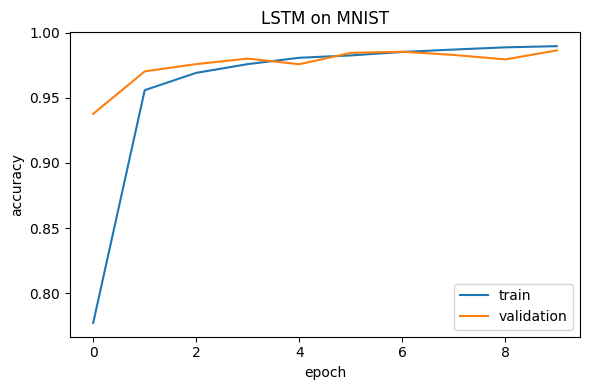

In [17]:
plt.figure(figsize=(6,4))
plt.plot(history.history['accuracy'],     label='train')
plt.plot(history.history['val_accuracy'], label='validation')   # TODO (Q4): which key holds val accuracy?
plt.xlabel('epoch'); plt.ylabel('accuracy'); plt.legend(); plt.title('LSTM on MNIST')
plt.tight_layout(); plt.show()

## Task 5 — Short-answer questions *(write your answers in this cell)*

1. Why do we feed the image as `(28, 28)` instead of flattening it to a 784-vector as in an MLP?
2. What is the role of the **hidden state** `h_t` versus the **cell state** `C_t` in the LSTM?
3. The final `Dense` layer uses **softmax**. Why softmax and not sigmoid here?
4. If you changed `LSTM(128)` to `LSTM(32)`, what would you expect to happen to accuracy and to
   the parameter count? Why?
5. Replace `activation='relu'` with the default `'tanh'`. Does the accuracy change? Which is
   recommended, and why?

> **Your answers:**
> 1. Feeding the image as `(28, 28)` treats it as a sequential series of rows, which preserves the spatial structure and dependencies from top to bottom. Flattening the image into a 784-vector completely discards this 2D sequence-like structure.
> 2. The **cell state ($C_t$)** serves as the long-term memory, running straight down the chain with minor linear interactions to prevent vanishing gradients. The **hidden state ($h_t$)** acts as the short-term working memory, storing filtered output information that gets passed to both the next cell and the output layer.
> 3. We use **softmax** because this is a mutually exclusive 10-class classification task; softmax forces the output scores to sum up to 1.0, representing a valid probability distribution. **Sigmoid** calculates independent probabilities for each class independently, which is suited for binary or multi-label classification.
> 4. The parameter count would drop substantially (from `params = 4 * [(28+128)*128 + 128] = 80,384` down to `4 * [(28+32)*32 + 32] = 7,808`), resulting in faster execution. However, the model's accuracy would likely decrease because 32 units provide less memory capacity to encode complex shapes.
> 5. The accuracy remains high (~98%), but `'tanh'` is highly recommended because it is the mathematical default for LSTMs and enables hardware acceleration (cuDNN kernels) on modern GPUs, resulting in much faster training runs.